In [3]:
from src.config import  ANALYTICAL_DATA_PATH
from src.styles import NHS_COLORS


import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [4]:
df = pd.read_csv(ANALYTICAL_DATA_PATH / 'combined.csv', parse_dates=['period'])

df.head()

,Region Code,Provider Code,Provider Name,Treatment Function Code,Treatment Function,>0-1,>1-2,>2-3,>3-4,>4-5,...,92nd percentile waiting time (in weeks),Total 52 plus weeks,Total 78 plus weeks,Total 65 plus weeks,% 52 plus weeks,period,month_name,month,year,month_label
0,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,94,177,129,133,155,...,37.207273,14,0,0,0.003093,2026-04-01,Apr,4,2026,Apr 2026
1,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,168,176,132,181,224,...,37.470526,37,0,0,NaN,2025-02-01,Feb,2,2025,Feb 2025
2,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,124,238,147,183,110,...,43.987500,171,5,34,NaN,2023-06-01,Jun,6,2023,Jun 2023
3,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,153,210,173,157,159,...,43.695000,162,8,35,NaN,2023-07-01,Jul,7,2023,Jul 2023
4,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,48,203,193,98,111,...,37.841000,10,0,0,0.002586,2025-03-01,Mar,3,2025,Mar 2025


In [5]:
df.info(verbose=True, show_counts=True)

selected_cols = [
    'Region Code',
    'Provider Code',
    'Provider Name',
    'Treatment Function Code',
    'Treatment Function',
    'Total number of incomplete pathways',
    'Total within 18 weeks',
    'Total 52 plus weeks',
    'Total 65 plus weeks',
    'Total 78 plus weeks',
    'Average (median) waiting time (in weeks)',
    '92nd percentile waiting time (in weeks)',
    'period',
    'month_label'
    
]

df_eda = df[selected_cols].copy()
# sort the values chronologically by date
df_eda = df_eda.sort_values(by='period').reset_index(drop=True)



<class 'pandas.DataFrame'>
RangeIndex: 43 entries, 0 to 42
Data columns (total 124 columns):
 #    Column                                    Non-Null Count  Dtype         
---   ------                                    --------------  -----         
 0    Region Code                               43 non-null     str           
 1    Provider Code                             43 non-null     str           
 2    Provider Name                             43 non-null     str           
 3    Treatment Function Code                   43 non-null     str           
 4    Treatment Function                        43 non-null     str           
 5    >0-1                                      43 non-null     int64         
 6    >1-2                                      43 non-null     int64         
 7    >2-3                                      43 non-null     int64         
 8    >3-4                                      43 non-null     int64         
 9    >4-5                            

In [6]:
df_eda.columns.to_list()

['Region Code',
 'Provider Code',
 'Provider Name',
 'Treatment Function Code',
 'Treatment Function',
 'Total number of incomplete pathways',
 'Total within 18 weeks',
 'Total 52 plus weeks',
 'Total 65 plus weeks',
 'Total 78 plus weeks',
 'Average (median) waiting time (in weeks)',
 '92nd percentile waiting time (in weeks)',
 'period',
 'month_label']

In [7]:
df_eda.info()

<class 'pandas.DataFrame'>
RangeIndex: 43 entries, 0 to 42
Data columns (total 14 columns):
 #   Column                                    Non-Null Count  Dtype         
---  ------                                    --------------  -----         
 0   Region Code                               43 non-null     str           
 1   Provider Code                             43 non-null     str           
 2   Provider Name                             43 non-null     str           
 3   Treatment Function Code                   43 non-null     str           
 4   Treatment Function                        43 non-null     str           
 5   Total number of incomplete pathways       43 non-null     int64         
 6   Total within 18 weeks                     43 non-null     int64         
 7   Total 52 plus weeks                       43 non-null     int64         
 8   Total 65 plus weeks                       43 non-null     int64         
 9   Total 78 plus weeks                       43 

In [8]:
df_eda.head()

,Region Code,Provider Code,Provider Name,Treatment Function Code,Treatment Function,Total number of incomplete pathways,Total within 18 weeks,Total 52 plus weeks,Total 65 plus weeks,Total 78 plus weeks,Average (median) waiting time (in weeks),92nd percentile waiting time (in weeks),period,month_label
0,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,3301,1973,209,81,30,14.285047,48.343077,2023-01-01,Jan 2023
1,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,3128,1838,198,71,19,13.358491,47.646667,2023-02-01,Feb 2023
2,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,3072,1867,179,48,3,12.474576,47.154286,2023-03-01,Mar 2023
3,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,3133,1945,163,57,4,11.951389,46.797778,2023-04-01,Apr 2023
4,Y62,RXN,LANCASHIRE TEACHING HOSPITALS NHS FOUNDATION T...,C_110,Trauma and Orthopaedic Service,3268,2144,163,43,5,10.900901,45.254286,2023-05-01,May 2023


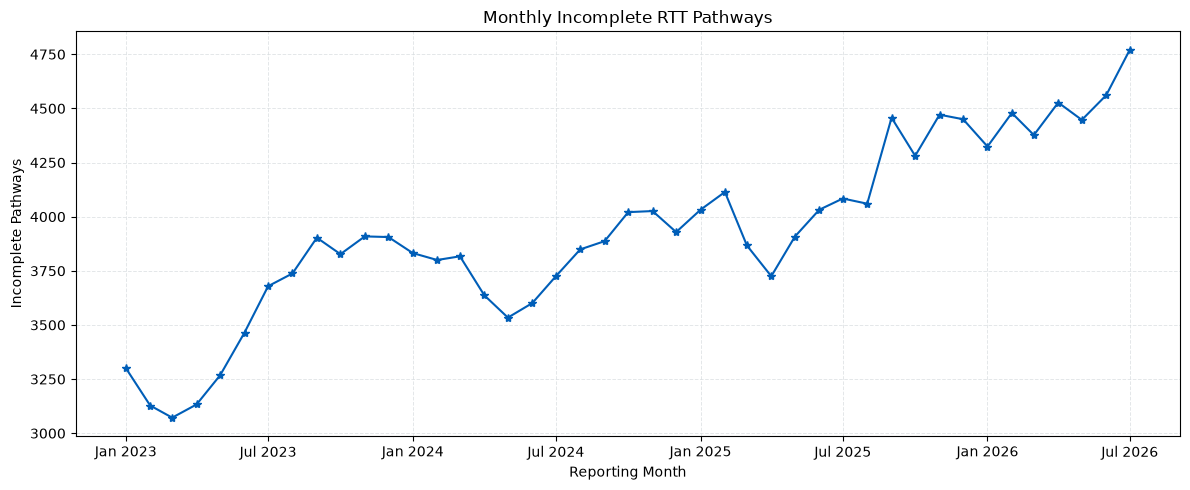

In [9]:
# plot the total incomplete pathways


fig, ax = plt.subplots(figsize=(12, 5))
ax.set_axisbelow(True)
ax.grid(
    True,
    axis="both",
    linestyle="--",
    linewidth=0.7,
    color=NHS_COLORS["grid"],
    alpha=0.7
)
ax.plot(
    df_eda["period"],
    df_eda["Total number of incomplete pathways"],
    color=NHS_COLORS["blue"],
    marker='*'
)
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

ax.set(
    title="Monthly Incomplete RTT Pathways",
    xlabel="Reporting Month",
    ylabel="Incomplete Pathways"
)


fig.tight_layout()
plt.show()


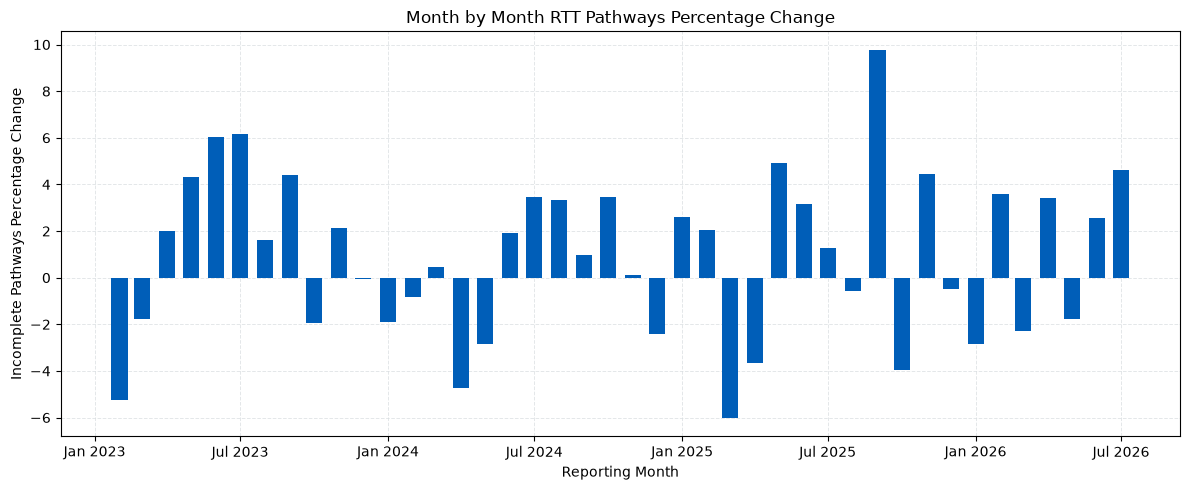

In [10]:
# plot the monthly change
df_eda['montly_pct_change'] = df_eda['Total number of incomplete pathways'].pct_change() * 100

fig, ax = plt.subplots(figsize=(12, 5))
ax.set_axisbelow(True)
ax.grid(
    True,
    axis="both",
    linestyle="--",
    linewidth=0.7,
    color=NHS_COLORS["grid"],
    alpha=0.7
)

ax.bar(
    df_eda['period'],
    df_eda['montly_pct_change'],
    width=20,
    color=NHS_COLORS["blue"]
)
ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)
ax.set(
    title="Month by Month RTT Pathways Percentage Change",
    xlabel="Reporting Month",
    ylabel="Incomplete Pathways Percentage Change"
)

fig.tight_layout()
plt.show()

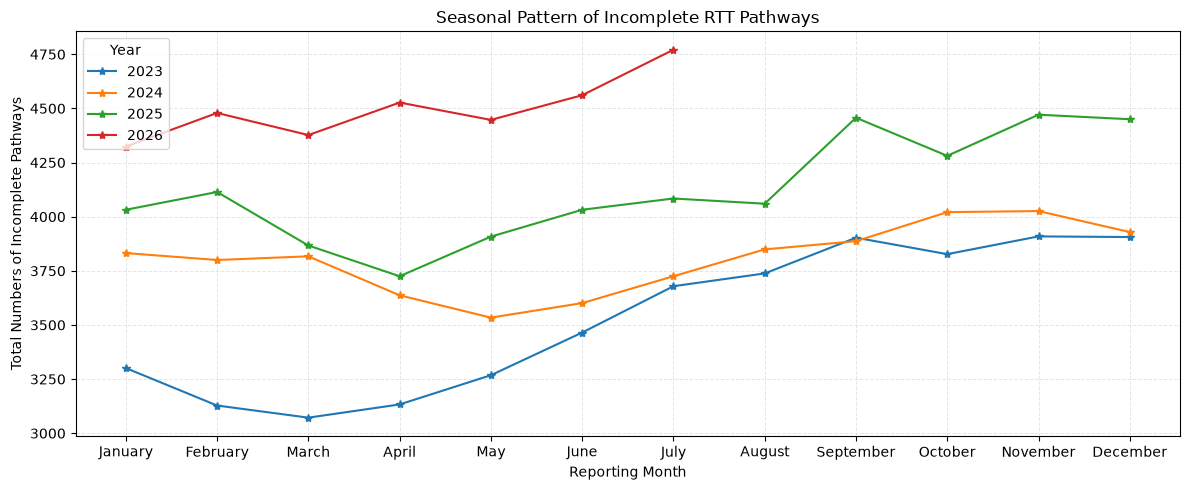

In [31]:
# Seasonal Pattern of Incomplete RTT Pathways
years = df_eda['period'].dt.year.unique()


fig, ax = plt.subplots(figsize=(12, 5))
ax.set_axisbelow(True)
ax.grid(
    True,
    axis="both",
    linestyle="--",
    linewidth=0.7,
    color=NHS_COLORS["grid"],
    alpha=0.7
)
for year in years:
    yearly_data = df_eda[df_eda['period'].dt.year == year]
    ax.plot(
        yearly_data['period'].dt.month_name(),
        yearly_data['Total number of incomplete pathways'],
        marker='*',
        label = str(year),
    )

ax.set(
    title="Seasonal Pattern of Incomplete RTT Pathways",
    xlabel="Reporting Month",
    ylabel="Total Numbers of Incomplete Pathways"
)
ax.legend(title="Year", loc="upper left")
fig.tight_layout()
plt.show()



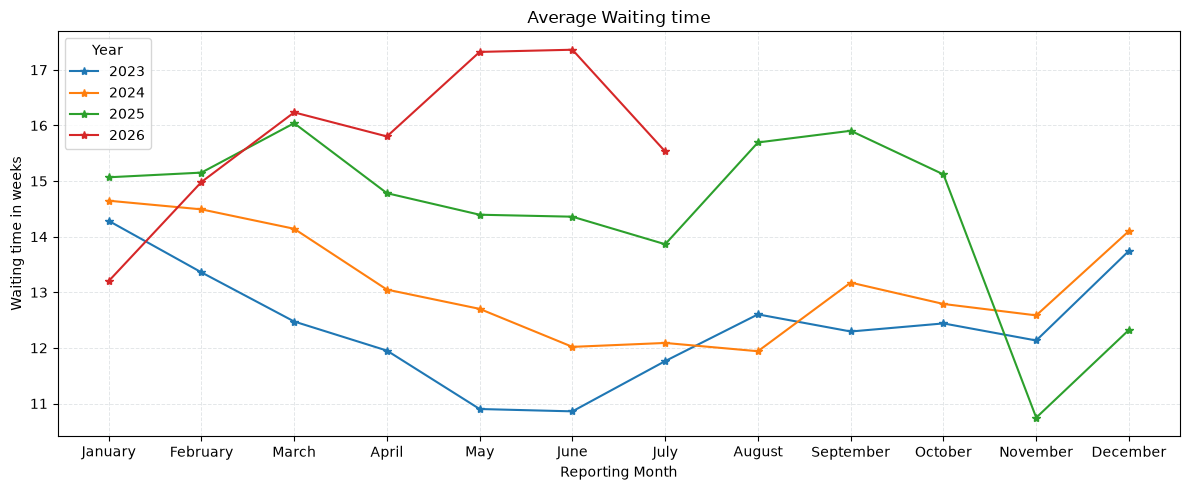

In [ ]:
# median waiting time for each year
# Seasonal Pattern of Incomplete RTT Pathways
years = df_eda['period'].dt.year.unique()


fig, ax = plt.subplots(figsize=(12, 5))
ax.set_axisbelow(True)
ax.grid(
    True,
    axis="both",
    linestyle="--",
    linewidth=0.7,
    color=NHS_COLORS["grid"],
    alpha=0.7
)
for year in years:
    yearly_data = df_eda[df_eda['period'].dt.year == year]
    # average median
    ax.plot(
        yearly_data['period'].dt.month_name(),
        yearly_data['Average (median) waiting time (in weeks)'],
        marker='*',
        label = str(year),
    )

ax.set(
    title="Average Median Waiting time",
    xlabel="Reporting Month",
    ylabel="Waiting time in weeks"
)
ax.legend(title="Year", loc="upper left")
fig.tight_layout()
plt.show()



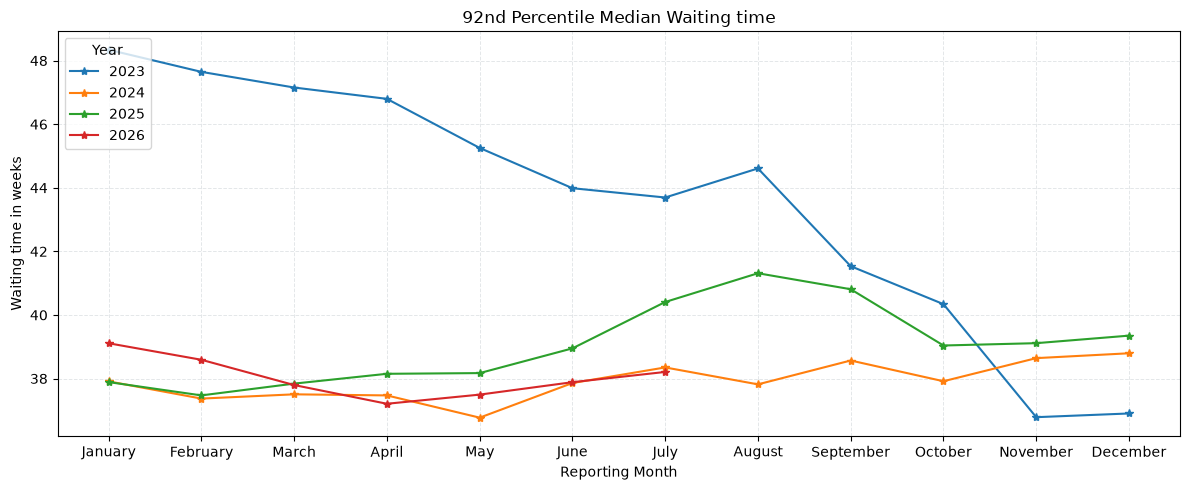

In [36]:
# 92nd percentile waiting time for each year

years = df_eda['period'].dt.year.unique()


fig, ax = plt.subplots(figsize=(12, 5))
ax.set_axisbelow(True)
ax.grid(
    True,
    axis="both",
    linestyle="--",
    linewidth=0.7,
    color=NHS_COLORS["grid"],
    alpha=0.7
)
for year in years:
    yearly_data = df_eda[df_eda['period'].dt.year == year]
    # average median
    ax.plot(
        yearly_data['period'].dt.month_name(),
        yearly_data['92nd percentile waiting time (in weeks)'],
        marker='*',
        label = str(year),
    )

ax.set(
    title="92nd Percentile Median Waiting time",
    xlabel="Reporting Month",
    ylabel="Waiting time in weeks"
)
ax.legend(title="Year", loc="upper left")
fig.tight_layout()
plt.show()



In [ ]:
"""
The observation from the Average median waiting time indicates an overall increase in the average waiting time year on year
however, each year, the direction of the average waiting time median is declining. the highest recorded decline is in 2025, where the average median collasped 
from a value of 15.9 weeks in sepetember of 2025 to 10.7 weeks in November.
A worthy observation is that, the average median time generally declines from march  to June, from 2023-2025, however, 2026 average waiting time
within this period goes the opposite direction
another important observation is that the average waiting time generally picks up in November of every year, as the year 2023-2025 shows that at this time patients
would most likely wait the longest
"""

df_eda['Average (median) waiting time (in weeks)'].loc[
    
    df_eda['period'].between('2025-09-01', '2025-11-01')
]